# Gravitational Time Dilation, Taylor-Series Contributions, and Particle-Triangle Comparisons

**Computational Relativity — mathematical exploration and visualization**

This notebook consolidates the discussion of triangular particle enumeration, the Lorentz-factor Taylor coefficients, gravitational time dilation in Schwarzschild spacetime, percentages by order, and decay versus radius. It also reproduces the **interactive gravitational comparison** using `ipywidgets`.

**Interpretation boundary:** The gravitational Taylor expansion is established mathematics for a stationary observer outside a spherical nonrotating mass. Assigning Taylor orders to particles or computational processes is a **proposed interpretation**, not a result implied by general relativity.

**Units:** The gravitational radius is $r_s=2GM/c^2$; plots use $r/r_s$ and dimensionless dilation. $r>r_s$ throughout.

## 1. Discrete particle triangle and geometry

If row $k$ contains $k$ particles, the first $n$ rows contain

$$N(n)=\sum_{k=1}^{n}k=\frac{n(n+1)}2.$$

For $n=6$, the rows contain $1,2,3,4,5,6$ particles, giving $N(6)=21$. A continuous triangle with base and perpendicular height both 6 has area $A=\tfrac12(6)(6)=18$ square units; particle count is not area. The *numerically equivalent* area $\tfrac12(6)(7)=21$ assumes an adjusted height and unit density. Actual geometric dimensions depend on dot spacing.

The central binomial coefficient $\binom{2n}{n}$ is **not** the same count: at $n=6$, $\binom{12}{6}=924$. It counts six-element selections from twelve positions.

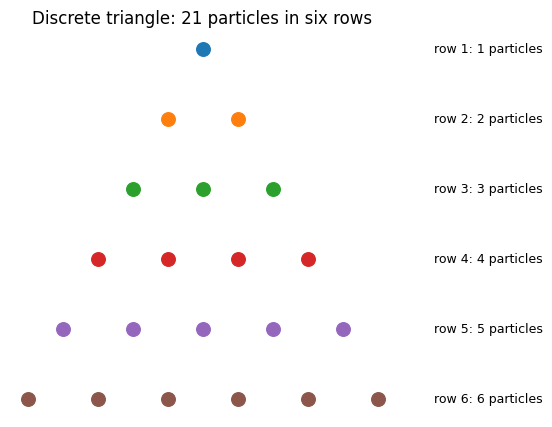

N(6) = 21 ; central binomial (12 choose 6) = 924


In [4]:
import math, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from pathlib import Path

fig,ax=plt.subplots(figsize=(8,5))
for k in range(1,7):
    xs=np.arange(k)-(k-1)/2
    ax.scatter(xs, np.full(k,k),s=95)
    ax.text(3.3,k,f"row {k}: {k} particles",va="center",fontsize=9)
ax.invert_yaxis(); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Discrete triangle: 21 particles in six rows')
plt.show()
print('N(6) =',6*7//2,'; central binomial (12 choose 6) =',math.comb(12,6))

## 2. Special relativity: Taylor coefficients

With $\beta=v/c$ and $x_v=\beta^2$,

$$\gamma_v=(1-x_v)^{-1/2}=\sum_{n=0}^{\infty}a_n x_v^n,\qquad a_n=\frac{\binom{2n}{n}}{4^n}.$$

The first terms are $1+\frac12x_v+\frac38x_v^2+\frac5{16}x_v^3+\frac{35}{128}x_v^4+\cdots$.

For an individual order $n\ge1$, define $D_{v,n}=a_nx_v^n$. Its limiting value as $x_v\to1^-$ is $a_n$; hence $D_{v,n}/a_n=x_v^n$. The full series has no finite maximum at $x_v=1$: it diverges.

## 3. Gravitational time dilation: Schwarzschild spacetime

For a stationary clock outside a spherical, nonrotating mass $M$, in Schwarzschild coordinates,

$$d\tau=dt\sqrt{1-\frac{2GM}{rc^2}},\qquad r_s=\frac{2GM}{c^2},\qquad x_g=\frac{r_s}{r}=\frac{2GM}{rc^2}.$$

The ratio of Schwarzschild coordinate time to local proper time is

$$\gamma_g=\frac{dt}{d\tau}=\frac1{\sqrt{1-x_g}}=1+\frac12x_g+\frac38x_g^2+\frac5{16}x_g^3+\cdots.$$

The **coefficients match** the special-relativistic Lorentz series; the physical variables differ ($x_v=v^2/c^2$ versus $x_g=r_s/r$). This applies to static clocks in the exterior region $r>r_s$, not arbitrary observers or arbitrary gravitational fields.

## 4. Gravitational contribution by Taylor order: percentages

For $n\ge1$,

$$D_{g,n}=a_n\left(\frac{r_s}{r}\right)^n,\qquad \text{percentage of baseline }1=100D_{g,n}\%.$$

At $r=10r_s$, $x_g=0.1$; at $r=2r_s$, $x_g=0.5$. The percentages below refer to the **baseline unity**, not to the total correction or to the fraction of all orders. $n=0$ is the baseline $1$ (100%).

In [10]:
orders=np.arange(1,7)
a=np.array([math.comb(2*int(n),int(n))/4**int(n) for n in orders])
rows=[]
for n,an in zip(orders,a):
    rows.append({'Order n':int(n),'a_n':an,'at r=10 r_s (%)':100*an*0.1**n,'at r=2 r_s (%)':100*an*0.5**n,
                 'n-th order radius scaling':f'1/r^{n}'})
df=pd.DataFrame(rows)


In [15]:
from IPython.display import display

formatted_df = df.copy()

for col in ['a_n', 'at r=10 r_s (%)', 'at r=2 r_s (%)']:
    formatted_df[col] = formatted_df[col].map(lambda x: f'{x:.9f}')

display(formatted_df)

print(
    'a_6 =',
    math.comb(12, 6),
    '/',
    4**6,
    '=',
    math.comb(12, 6) / 4**6
)

,Order n,a_n,at r=10 r_s (%),at r=2 r_s (%),n-th order radius scaling
0,1,0.500000000,5.000000000,25.000000000,1/r^1
1,2,0.375000000,0.375000000,9.375000000,1/r^2
2,3,0.312500000,0.031250000,3.906250000,1/r^3
3,4,0.273437500,0.002734375,1.708984375,1/r^4
4,5,0.246093750,0.000246094,0.769042969,1/r^5
5,6,0.225585938,0.000022559,0.352478027,1/r^6


a_6 = 924 / 4096 = 0.2255859375


## 5. Interactive comparison (adjust the gravitational parameter)

Use the slider to vary $x_g=r_s/r$ between 0.05 and 0.90. Each bar is an order's **percentage contribution to the baseline**. The bar lengths are scaled to the first-order contribution for visual comparison. The panel also displays the exact factor, the first-six-order approximation, and their difference.

Run this cell in Jupyter Notebook/JupyterLab with `ipywidgets` installed. If the widget is unavailable, the fallback below draws a static comparison at $x_g=0.1$.

Install ipywidgets for the interactive slider: %pip install ipywidgets


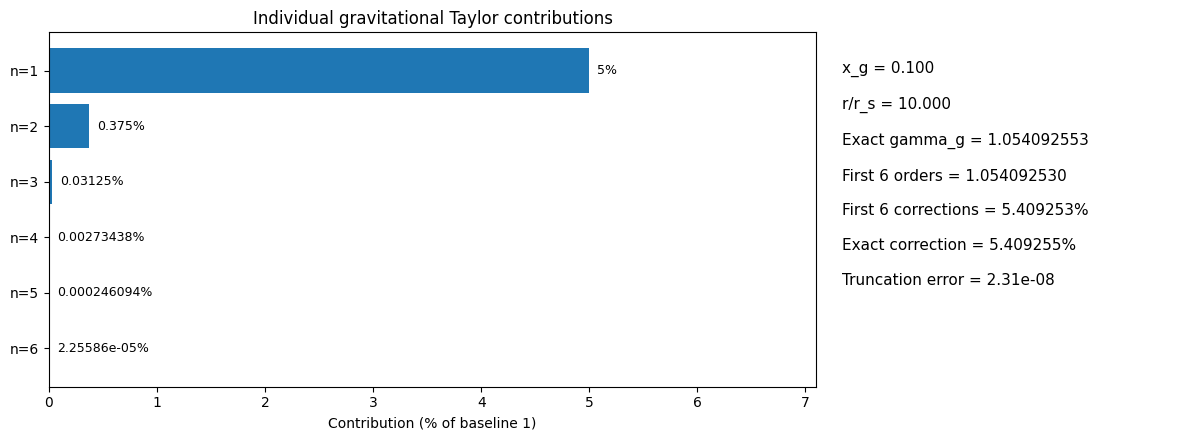

In [19]:
def gravitational_panel(x=0.10):
    x=float(x)
    n=np.arange(1,7)
    coeff=np.array([math.comb(2*int(k),int(k))/4**int(k) for k in n])
    terms=coeff*x**n
    exact=1/np.sqrt(1-x)
    approx=1+terms.sum()
    fig,(ax,info)=plt.subplots(1,2,figsize=(12,4.5),gridspec_kw={'width_ratios':[2.2,1]})
    ax.barh(n,100*terms)
    ax.invert_yaxis();ax.set_yticks(n);ax.set_yticklabels([f'n={k}' for k in n]);ax.set_xlabel('Contribution (% of baseline 1)')
    ax.set_title('Individual gravitational Taylor contributions')
    for k,v in zip(n,terms): ax.text(100*v+max(100*terms)*.015,k,f'{100*v:.6g}%',va='center',fontsize=9)
    ax.set_xlim(0,max(100*terms)*1.42)
    info.axis('off')
    lines=[f'x_g = {x:.3f}',f'r/r_s = {1/x:.3f}',f'Exact gamma_g = {exact:.9f}',f'First 6 orders = {approx:.9f}',
           f'First 6 corrections = {100*terms.sum():.6f}%',f'Exact correction = {100*(exact-1):.6f}%',f'Truncation error = {exact-approx:.3g}']
    info.text(.03,.92,'\n\n'.join(lines),va='top',fontsize=11,transform=info.transAxes)
    plt.tight_layout();plt.show()

try:
    import ipywidgets as widgets
    from IPython.display import display
    display(widgets.interactive(gravitational_panel,x=widgets.FloatSlider(value=.1,min=.05,max=.90,step=.05,description='x_g',continuous_update=False)))
except ImportError:
    print('Install ipywidgets for the interactive slider: %pip install ipywidgets')
    gravitational_panel(.1)

## 6. Decay versus distance: gravitational time-dilation terms

Since $x_g=r_s/r$, each order obeys

$$D_{g,n}(r)=a_n\left(\frac{r_s}{r}\right)^n\propto r^{-n}.$$

Thus $n=1$ decays as $1/r$, $n=2$ as $1/r^2$, and $n=3$ as $1/r^3$. **Newtonian gravitational acceleration** itself follows $g=GM/r^2$; the $n=2$ correction to $\gamma_g$ having $1/r^2$ dependence does *not* make it the Newtonian force term. For weak fields, $\gamma_g-1\approx GM/(rc^2)$, proportional to $1/r$.

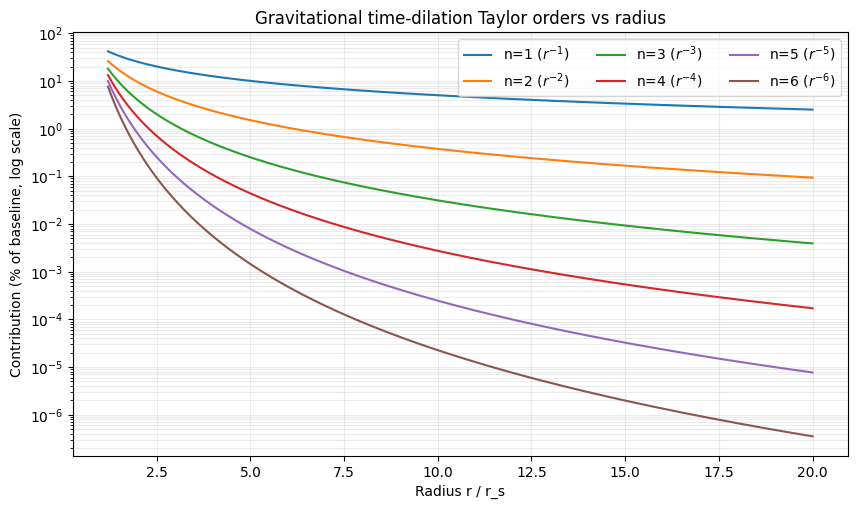

In [20]:
r_over_rs=np.linspace(1.2,20,600)
fig,ax=plt.subplots(figsize=(10,5.5))
for n in range(1,7):
    an=math.comb(2*n,n)/4**n
    ax.plot(r_over_rs,100*an/r_over_rs**n,label=f'n={n} ($r^{{-{n}}}$)')
ax.set_yscale('log');ax.set_xlabel('Radius r / r_s');ax.set_ylabel('Contribution (% of baseline, log scale)')
ax.set_title('Gravitational time-dilation Taylor orders vs radius');ax.grid(True,which='both',alpha=.25);ax.legend(ncol=3)
plt.show()

## 7. Gravity versus computational / motion contributions

In the proposed computational interpretation, order $n$ is associated with a particle or multiplicity sector. The *mathematical* comparison is

$$D_{v,n}=a_n\left(\frac{v^2}{c^2}\right)^n,\qquad D_{g,n}=a_n\left(\frac{r_s}{r}\right)^n.$$

These contributions are numerically equal if the **dimensionless inputs** coincide, $v^2/c^2=r_s/r$. This equality is algebraic and does not establish a common microscopic mechanism. At a fixed subluminal $v$, motion terms decay geometrically with order; gravitational terms at a fixed exterior radius do likewise. At their limiting inputs approaching one, the coefficients decay asymptotically as $a_n\sim1/\sqrt{\pi n}$, **not** an inverse-square law.

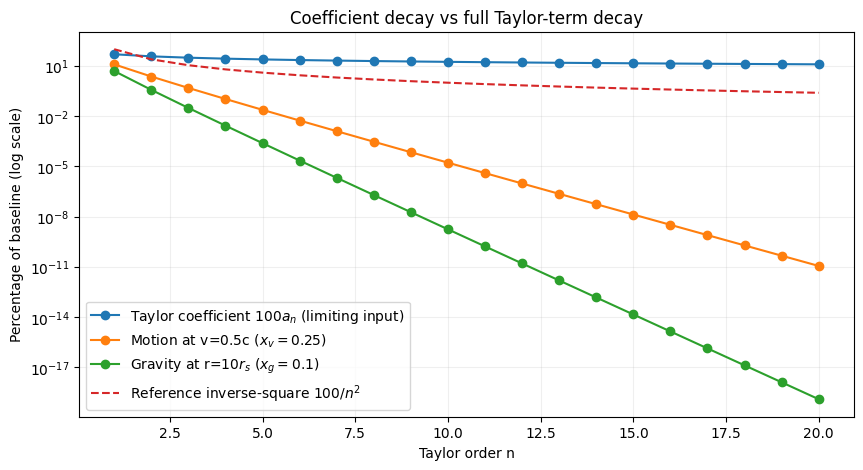

In [21]:
n=np.arange(1,21)
coeff=np.array([math.comb(2*int(k),int(k))/4**int(k) for k in n])
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(n,100*coeff,'o-',label='Taylor coefficient $100a_n$ (limiting input)')
ax.plot(n,100*coeff*.25**n,'o-',label='Motion at v=0.5c ($x_v=0.25$)')
ax.plot(n,100*coeff*.1**n,'o-',label='Gravity at r=10$r_s$ ($x_g=0.1$)')
ax.plot(n,100/n**2,'--',label='Reference inverse-square $100/n^2$')
ax.set_yscale('log');ax.set_xlabel('Taylor order n');ax.set_ylabel('Percentage of baseline (log scale)')
ax.set_title('Coefficient decay vs full Taylor-term decay');ax.grid(True,which='both',alpha=.2);ax.legend();plt.show()

## 8. Earlier comparison infographic (historical illustration)

The earlier graphic is included for continuity with the discussion. **Correction:** Its headline incorrectly suggests that Taylor coefficients and gravity both follow the same inverse-square decay; they do not. Some table/plot labels are also inconsistent. The computed tables and graphs in this notebook supersede those claims.

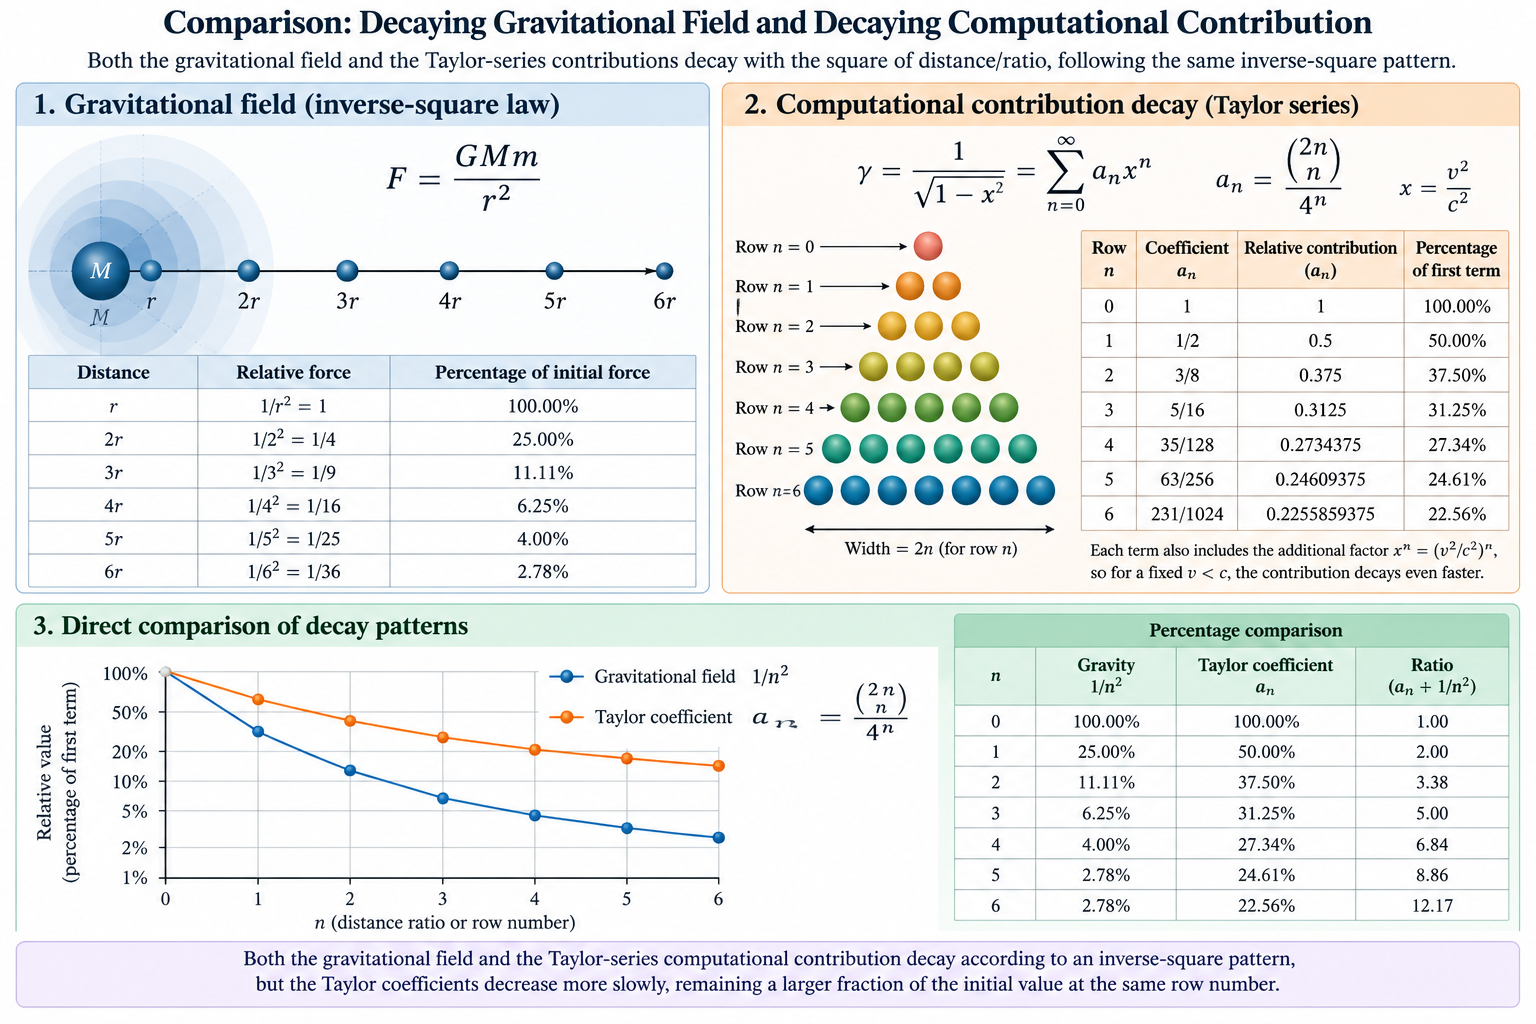

## 9. Interpretation and limitations

1. A discrete triangular population of $n(n+1)/2$ particles is a geometric/combinatorial construction; it does not imply the central binomial coefficient $\binom{2n}{n}$.
2. The Taylor coefficient $a_n=\binom{2n}{n}/4^n$ is an exact identity in both dilation expansions.
3. The individual $n$-th term has limiting value $a_n$ as the input approaches 1, but the *full* dilation factor diverges at that limit.
4. A particle-enumeration interpretation requires a physical rule mapping rows/configurations to $a_n$ and an independently testable prediction.
5. The Schwarzschild expression is a coordinate-time/proper-time ratio for static clocks outside a spherical nonrotating mass, not a universal gravitational time-dilation formula for all geometries.

**Reproducibility:** Execute the notebook top-to-bottom. Dependencies: NumPy, pandas, Matplotlib, IPython, ipywidgets.